# CSC173 · Lecture 01 · Introduction to Deep Learning
## Session demo with TensorFlow (Keras)

Jennifer Joyce M. Montemayor · Department of Computer Science, MSU-IIT

This notebook follows the lecture, in order:

1. One perceptron by hand, then as a Keras `Dense` layer
2. Why we need non-linear activation functions
3. Our backpropagation example, checked with `tf.GradientTape`
4. Gradient descent and the learning rate
5. *Will I pass this class?* A complete Keras model
6. Exercises

**How to run:** open it in Google Colab (TensorFlow is already installed) or in Jupyter with `pip install tensorflow matplotlib`. Run the cells from top to bottom.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import time

tf.keras.utils.set_random_seed(173)   # same random numbers every run, so results are repeatable
print("TensorFlow", tf.__version__)

TensorFlow 2.22.0-rc0


---
## 1. One perceptron

From the lecture: $\hat{y} = g(w_0 + X^T W)$ with $w_0 = 1$, $W = \begin{bmatrix}3\\-2\end{bmatrix}$ and input $X = \begin{bmatrix}-2\\4\end{bmatrix}$.

### 1a. By hand with NumPy

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

w0 = 1.0                      # bias
W  = np.array([3.0, -2.0])    # weights
X  = np.array([-1.0, -1.0])    # one input example

z = w0 + X @ W                # weighted sum: 1 + (3 * -2) + (-2 * 4)
y_hat = sigmoid(z)            # non-linear activation

print("z     =", z)
print("y_hat =", y_hat)

z     = 0.0
y_hat = 0.5


`z = -13`, so the point is far on the "0" side of the line $1 + 3x_1 - 2x_2 = 0$, and the sigmoid gives a number very close to 0.

**Try it:** change `X` to `[1, 1]`. You should get $z = 2$ and $\hat{y} \approx 0.88$.

### 1b. The same perceptron as a Keras `Dense` layer

A `Dense(1)` layer *is* a perceptron. We copy our weights into it and get the same answer.

### Exercise 1. **Perceptron:** in section 1, find an input $X$ that gives exactly $\hat{y} = 0.5$. (Hint: it must lie on the line $1 + 3x_1 - 2x_2 = 0$.)

$\hat{y} = 0$ when the equation $1 + 3x_1 - 2x_2 = 0$ is true. 
This is achieved with $x_1$ and $x_2$ are -1.0 

$1 + 3 * -1.0 - 2 * -1.0$
$ = 1 - 3 + 2 $
$ = 0$

In [3]:
layer = tf.keras.layers.Dense(units=1, activation="sigmoid")
layer.build(input_shape=(None, 2))                     # 2 inputs -> creates the weights
layer.set_weights([np.array([[3.0], [-2.0]]),          # kernel W (shape 2 x 1)
                   np.array([1.0])])                   # bias w0

print("Keras output:", layer(np.array([[-2.0, 4.0]])).numpy())

Keras output: [[2.2603242e-06]]


---
## 2. Why non-linear activation functions?

We make a dataset that a straight line cannot separate (two interleaving half-moons), then train two models:

* **Linear model:** no hidden layer. Its decision boundary is a straight line.
* **Small neural network:** one hidden layer with ReLU. It can bend the boundary.

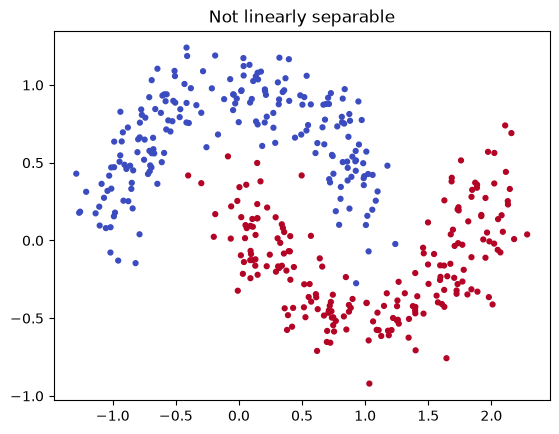

In [4]:
def make_moons(n=400, noise=0.15):
    t = np.random.rand(n // 2) * np.pi
    a = np.c_[np.cos(t), np.sin(t)]                    # upper moon -> class 0
    b = np.c_[1 - np.cos(t), 0.5 - np.sin(t)]          # lower moon -> class 1
    X = np.vstack([a, b]) + noise * np.random.randn(n, 2)
    y = np.r_[np.zeros(n // 2), np.ones(n // 2)]
    return X.astype("float32"), y.astype("float32")

X_moons, y_moons = make_moons()
plt.scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons, cmap="coolwarm", s=12)
plt.title("Not linearly separable"); plt.show()

In [5]:
linear_model = tf.keras.Sequential([
    tf.keras.Input(shape=(2,)),
    tf.keras.layers.Dense(1, activation="sigmoid"),     # a single perceptron
])

nonlinear_model = tf.keras.Sequential([
    tf.keras.Input(shape=(2,)),
    tf.keras.layers.Dense(16, activation="relu"),       # hidden layer with a non-linearity
    tf.keras.layers.Dense(1, activation="sigmoid"),
])

for m in (linear_model, nonlinear_model):
    m.compile(optimizer=tf.keras.optimizers.Adam(0.05), loss="binary_crossentropy", metrics=["accuracy"])
    m.fit(X_moons, y_moons, epochs=150, verbose=0)

print("Linear model accuracy:     %.2f" % linear_model.evaluate(X_moons, y_moons, verbose=0)[1])
print("Neural network accuracy:   %.2f" % nonlinear_model.evaluate(X_moons, y_moons, verbose=0)[1])

Linear model accuracy:     0.93
Neural network accuracy:   1.00


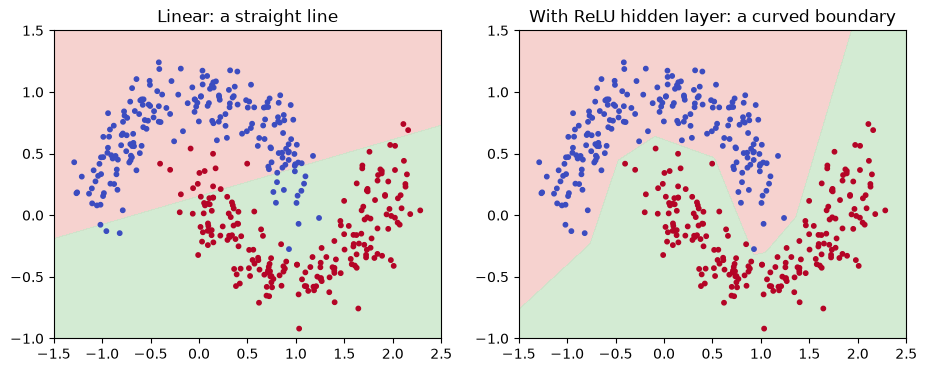

In [6]:
def plot_boundary(model, X, y, ax, title):
    xx, yy = np.meshgrid(np.linspace(-1.5, 2.5, 200), np.linspace(-1, 1.5, 200))
    grid = np.c_[xx.ravel(), yy.ravel()].astype("float32")
    p = model.predict(grid, verbose=0).reshape(xx.shape)
    ax.contourf(xx, yy, p, levels=[0, 0.5, 1], colors=["#f4c7c3", "#c8e6c9"], alpha=0.8)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=10)
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_boundary(linear_model, X_moons, y_moons, axes[0], "Linear: a straight line")
plot_boundary(nonlinear_model, X_moons, y_moons, axes[1], "With ReLU hidden layer: a curved boundary")
plt.show()

**Discuss:** replace `activation="relu"` with `activation=None` (or `"linear"`) in the hidden layer and re-run. Why does accuracy drop back to the linear model's level?

---
## 3. Our backpropagation example, checked by TensorFlow

The network from the lecture: inputs $i_1 = 0.05$, $i_2 = 0.10$; targets $o_1 = 0.01$, $o_2 = 0.99$; sigmoid everywhere; error $E = \tfrac12\sum(\text{actual} - \text{predicted})^2$; learning rate $0.3$.

`tf.GradientTape` records the forward pass and then computes every $\partial E / \partial w$ for us. This is backpropagation, done automatically.

In [7]:
i = tf.constant([0.05, 0.10])
target = tf.constant([0.01, 0.99])

w1, w2, w3, w4 = [tf.Variable(v) for v in (0.15, 0.20, 0.25, 0.30)]
w5, w6, w7, w8 = [tf.Variable(v) for v in (0.40, 0.45, 0.50, 0.55)]
b1, b2, b3, b4 = 0.35, 0.35, 0.60, 0.60

with tf.GradientTape() as tape:
    # forward propagation (same equations as the slides)
    z1 = i[0] * w1 + i[1] * w3 + b1;  h1 = tf.sigmoid(z1)
    z2 = i[0] * w2 + i[1] * w4 + b2;  h2 = tf.sigmoid(z2)
    z3 = h1 * w5 + h2 * w7 + b3;      o1 = tf.sigmoid(z3)
    z4 = h1 * w6 + h2 * w8 + b4;      o2 = tf.sigmoid(z4)
    E = 0.5 * ((target[0] - o1) ** 2 + (target[1] - o2) ** 2)

print(f"h1 = {h1.numpy():.4f}   h2 = {h2.numpy():.4f}")
print(f"o1 = {o1.numpy():.4f}   o2 = {o2.numpy():.4f}")
print(f"E  = {E.numpy():.5f}")

dE_dw5, dE_dw1, dE_dw6 = tape.gradient(E, [w5, w1, w6])
lr = 0.3
print(f"\ndE/dw5 = {dE_dw5.numpy():.4f}   ->  new w5 = 0.40 - 0.3 * {dE_dw5.numpy():.4f} = {0.40 - lr * dE_dw5.numpy():.4f}")
print(f"dE/dw1 = {dE_dw1.numpy():.6f} ->  new w1 = 0.15 - 0.3 * {dE_dw1.numpy():.6f} = {0.15 - lr * dE_dw1.numpy():.4f}")
print(f"dE/dw6 = {dE_dw6.numpy():.6f} ->  new w6 = 0.45 - 0.3 * {dE_dw6.numpy():.6f} = {0.45 - lr * dE_dw6.numpy():.4f}")

h1 = 0.5945   h2 = 0.5963
o1 = 0.7569   o2 = 0.7677
E  = 0.30366

dE/dw5 = 0.0817   ->  new w5 = 0.40 - 0.3 * 0.0817 = 0.3755
dE/dw1 = 0.000448 ->  new w1 = 0.15 - 0.3 * 0.000448 = 0.1499
dE/dw6 = -0.023564 ->  new w6 = 0.45 - 0.3 * -0.023564 = 0.4571


These match the slides (TensorFlow keeps more decimals, so the 4th decimal can differ by 1): $\partial E/\partial w_5 \approx 0.0816$ (new $w_5 \approx 0.3755$) and $\partial E/\partial w_1 \approx 0.00045$ (new $w_1 \approx 0.1499$).

Now let TensorFlow repeat the update many times and watch the error fall. This loop is gradient descent: **forward pass → loss → gradients → update**.

error after 1 step: 0.30366   after 2000 steps: 0.000881
outputs now: o1 = 0.040 (target 0.01), o2 = 0.961 (target 0.99)


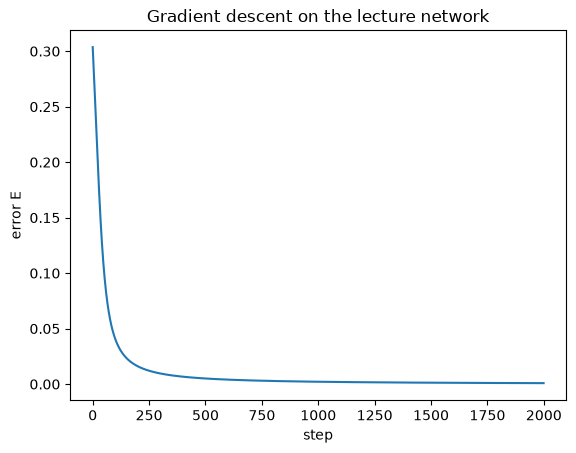

In [8]:
weights = [w1, w2, w3, w4, w5, w6, w7, w8]
optimizer = tf.keras.optimizers.SGD(learning_rate=0.3)
history = []

for step in range(2000):
    with tf.GradientTape() as tape:
        h1 = tf.sigmoid(i[0] * w1 + i[1] * w3 + b1)
        h2 = tf.sigmoid(i[0] * w2 + i[1] * w4 + b2)
        o1 = tf.sigmoid(h1 * w5 + h2 * w7 + b3)
        o2 = tf.sigmoid(h1 * w6 + h2 * w8 + b4)
        E = 0.5 * ((target[0] - o1) ** 2 + (target[1] - o2) ** 2)
    grads = tape.gradient(E, weights)                 # backpropagation
    optimizer.apply_gradients(zip(grads, weights))    # W <- W - lr * dE/dW
    history.append(E.numpy())

print(f"error after 1 step: {history[0]:.5f}   after 2000 steps: {history[-1]:.6f}")
print(f"outputs now: o1 = {o1.numpy():.3f} (target 0.01), o2 = {o2.numpy():.3f} (target 0.99)")
plt.plot(history); plt.xlabel("step"); plt.ylabel("error E"); plt.title("Gradient descent on the lecture network"); plt.show()

---
## 4. Gradient descent and the learning rate

The update rule is $W \leftarrow W - \eta \,\dfrac{\partial J}{\partial W}$. Here we minimise the simple function $f(x) = (x - 2)^2$, whose slope is $f'(x) = 2(x - 2)$, starting from $x = 9$ with three learning rates.

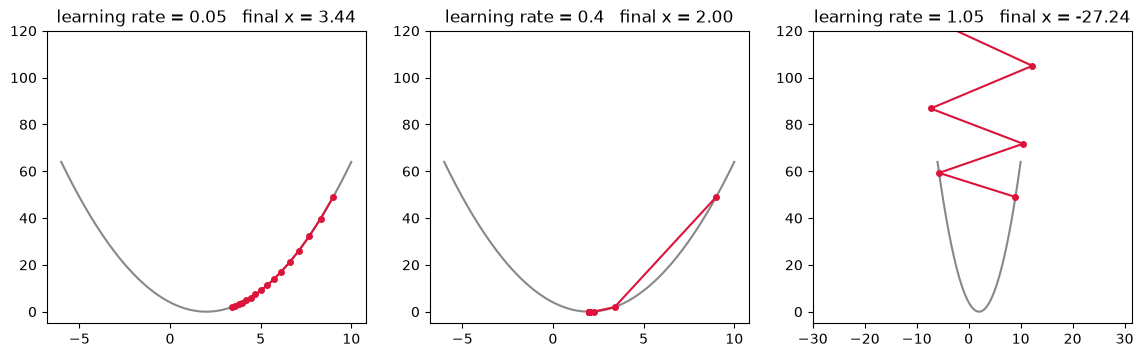

In [9]:
def gradient_descent(lr, x=9.0, steps=15):
    path = [x]
    for _ in range(steps):
        grad = 2 * (x - 2)       # derivative of (x - 2)^2
        x = x - lr * grad        # the update rule
        path.append(x)
    return np.array(path)

xs = np.linspace(-6, 10, 200)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, lr in zip(axes, [0.05, 0.4, 1.05]):
    p = gradient_descent(lr)
    ax.plot(xs, (xs - 2) ** 2, color="#888")
    ax.plot(p, (p - 2) ** 2, "o-", color="crimson", ms=4)
    ax.set_ylim(-5, 120); ax.set_title(f"learning rate = {lr}   final x = {p[-1]:.2f}")
plt.show()

* **0.05 (too small):** slow, still far from the minimum $x = 2$ after 15 steps.
* **0.4 (good):** reaches the minimum quickly.
* **1.05 (too big):** each step overshoots further and the method diverges.

---
## 5. Will I pass this class?

Features: $x_1$ = activities and assignments passed (0–10), $x_2$ = hours spent on the final project (0–10). Label: 1 = pass, 0 = fail.

> The data below is **synthetic** (generated for the demo), not real student records.

students: 200   passed: 107   failed: 93


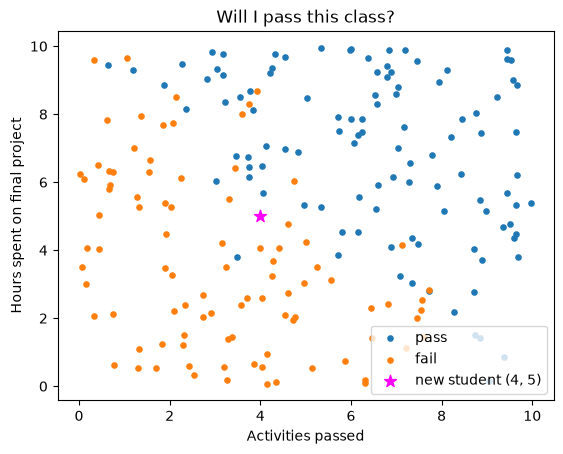

In [10]:
n = 200
activities = np.random.uniform(0, 10, n)
hours      = np.random.uniform(0, 10, n)
score = 0.6 * activities + 0.5 * hours + np.random.normal(0, 1.0, n)   # hidden "true" rule plus noise
passed = (score > 5.5).astype("float32")

X = np.c_[activities, hours].astype("float32")
y = passed
print("students:", n, "  passed:", int(y.sum()), "  failed:", int(n - y.sum()))

plt.scatter(activities[y == 1], hours[y == 1], label="pass", s=14)
plt.scatter(activities[y == 0], hours[y == 0], label="fail", s=14)
plt.scatter([4], [5], c="magenta", s=80, marker="*", label="new student (4, 5)")
plt.xlabel("Activities passed"); plt.ylabel("Hours spent on final project"); plt.legend(); plt.title("Will I pass this class?")
plt.show()

### Split the data

We keep 25% of the students aside as a **test set**. The model never trains on them, so they tell us how well it works on new students.

In [11]:
idx = np.random.permutation(n)
train, test = idx[:150], idx[150:]
X_train, y_train, X_test, y_test = X[train], y[train], X[test], y[test]

### Build, compile, train

Exactly the network from the slides: 2 inputs → 3 hidden units → 1 output.

In [12]:
def modelsig():
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(2,)),                      # x1, x2
        tf.keras.layers.Normalization(),                 # rescale inputs to mean 0, std 1 (helps training)
        tf.keras.layers.Dense(3, activation="sigmoid"),  # hidden layer: z1, z2, z3
        tf.keras.layers.Dense(1, activation="sigmoid"),  # output: probability of passing
    ], name = "sigmoid")
    return model

def modelrel():
    model = tf.keras.Sequential([
        tf.keras.Input(shape=(2,)),                      # x1, x2
        tf.keras.layers.Normalization(),                 # rescale inputs to mean 0, std 1 (helps training)
        tf.keras.layers.Dense(3, activation="relu"),  # hidden layer: z1, z2, z3
        tf.keras.layers.Dense(1, activation="sigmoid"),  # output: probability of passing
    ], name = "relu")
    return model

def modelsum(fn):
    m = fn()
    m.layers[0].adapt(X_train)                      # learn the mean and std from the training data
    m.summary()

modelsum(modelsig)
modelsum(modelrel)

Model: "sigmoid"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ normalization (Normalization)        │ (None, 2)                   │               5 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 3)                   │               9 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │               4 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 18 (76.00 B)

 Trainable params: 13 (52.00 B)

 Non-trainable params: 5 (24.00 B)

Model: "relu"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ normalization_1 (Normalization)      │ (None, 2)                   │               5 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 3)                   │               9 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 1)                   │               4 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 18 (76.00 B)

 Trainable params: 13 (52.00 B)

 Non-trainable params: 5 (24.00 B)

Count the trainable parameters: `Dense(3)` has $2 \times 3 + 3 = 9$, `Dense(1)` has $3 \times 1 + 1 = 4$, so **13** in total. (The `Normalization` layer's mean and variance are not trained by gradient descent.)

In [13]:
def bm(fn, bsz):
    m = fn()
    m.compile(
        optimizer=tf.keras.optimizers.SGD(learning_rate=0.5),
        loss="binary_crossentropy",          # pass/fail -> cross-entropy
        metrics=["accuracy"],
    )
    
    before = m.predict(np.array([[4.0, 5.0]]), verbose=0)[0, 0]
    s = time.perf_counter()
    history = m.fit(X_train, y_train, epochs=200, batch_size=bsz,
                        validation_data=(X_test, y_test), verbose=0)
    t = time.perf_counter() - s
    after = m.predict(np.array([[4.0, 5.0]]), verbose=0)[0, 0]

    a = m.evaluate(X_test, y_test, verbose=0)[1]

    return history, before, after, t, a, bsz    
    
batch_sizes = [1, 16, 150]
batch_labels = {1: "s", 16: "mb", 150: "fb"}
models = {"sigmoid": modelsig, "relu": modelrel}

results = {}

for name, fn in models.items():
    for bs in batch_sizes:
        history, before, after, t, a, bsz = bm(fn, bs)        
        key = f"{name}_{batch_labels[bs]}"
        results[key] = {
            "model": name,
            "batch_size": bs,
            "batch_label": batch_labels[bs],
            "before": before,
            "after": after,
            "test_accuracy": a,
            "time_seconds": t,
            "history": history
        }

for k, v in results.items():
    print(f"Model = {v['model']} batch size = {v['batch_size']:.3f}")
    print(f"New student (4, 5): before training {v['before']:.2f}, after training {v['after']:.2f}")
    print(f"Test accuracy: {v['test_accuracy']:.3f}")
    print(f"Time taken: {v['time_seconds']:.2f}s")

Model = sigmoid batch size = 1.000
New student (4, 5): before training 0.57, after training 0.33
Test accuracy: 0.480
Time taken: 52.48s
Model = sigmoid batch size = 16.000
New student (4, 5): before training 0.18, after training 0.11
Test accuracy: 0.820
Time taken: 20.53s
Model = sigmoid batch size = 150.000
New student (4, 5): before training 0.41, after training 0.36
Test accuracy: 0.840
Time taken: 14.64s
Model = relu batch size = 1.000
New student (4, 5): before training 0.69, after training 0.39
Test accuracy: 0.480
Time taken: 48.81s
Model = relu batch size = 16.000
New student (4, 5): before training 0.50, after training 0.51
Test accuracy: 0.520
Time taken: 19.00s
Model = relu batch size = 150.000
New student (4, 5): before training 0.54, after training 0.90
Test accuracy: 0.700
Time taken: 16.61s


### Exercise 2. **Activations:** in section 5, change the hidden activation from `"sigmoid"` to `"relu"`. Does training get faster?

As can be seen from the results from the benchmark above, running the hidden activation with relu instead of sigmoid effectively makes the training much faster. This difference becomes much more apparent with longer epochs. However, this yielded lower accuracy.

### Exercise 3. **Batch size:** train with `batch_size=1` (stochastic), `16` (mini-batch) and `150` (full batch). Compare the loss curves and the time taken.
The setup has been configured to consider three sets of batch sizes for both sigmoid and relu models. The results have revealed that for this particular experiment, the sigmoid model run at a full batch gradient descent yielded the best test accuracy set at 84% witha  training time of 15.42s which is only 1s slower than the fastest run which is that of the ReLU full batch. Sigmoid mini-batch came in second with 82% test accuracy and 17.97s of time taken. 

ReLU on the other hand performed faster in all batch sizes, however, they have yielded significantly worse test accuracies. Moreover, the most accuracte test for this model is the batch size which has yielded 70%, however, this is still lower than that of the sigmoid runs.

Across all runs, the time taken has been reduced significantly moving from stochastic to mini batch and then the fastest with the full batch runs.


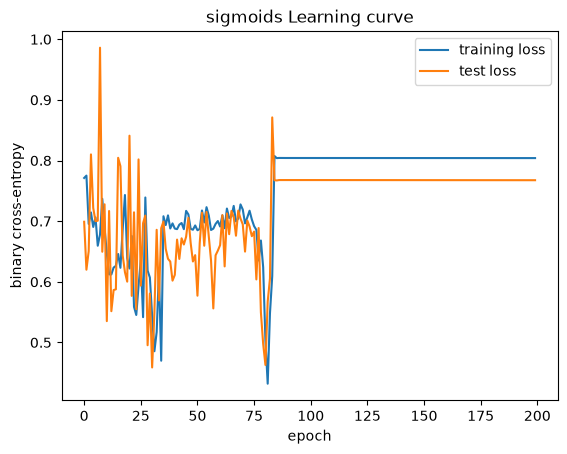

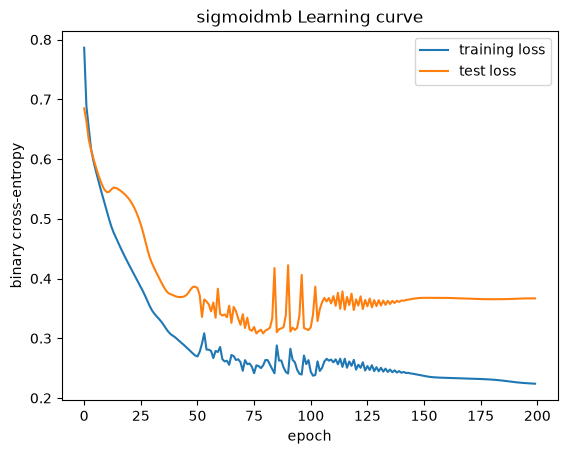

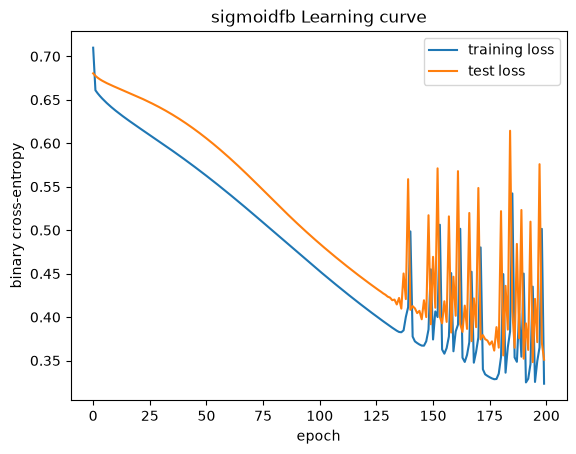

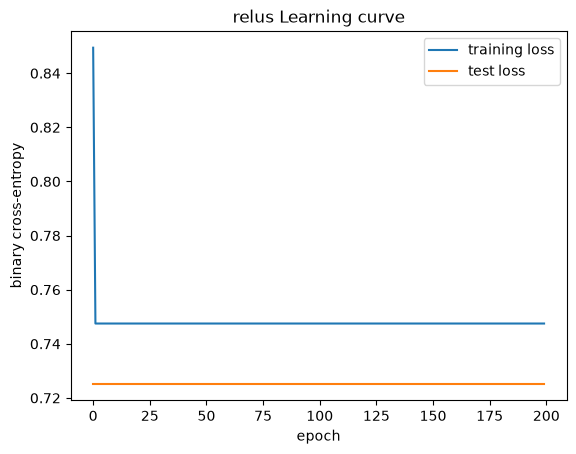

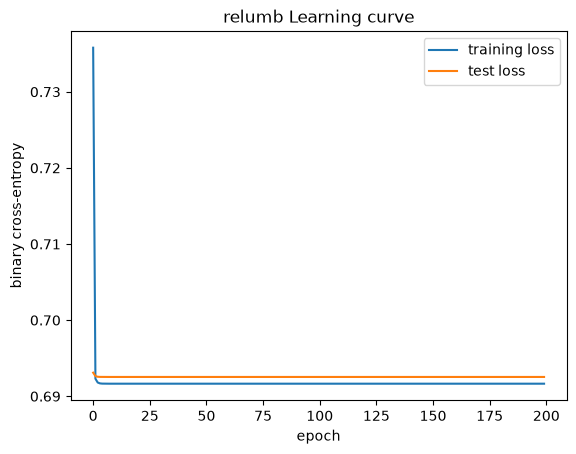

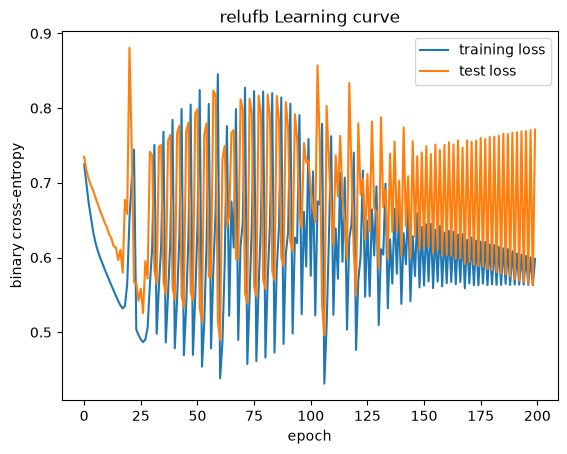

In [14]:
for k, v in results.items():
    history = v['history']
    model = v['model']
    batch_label = v['batch_label']
    name = model + batch_label
    plt.plot(history.history["loss"], label="training loss")
    plt.plot(history.history["val_loss"], label="test loss")
    plt.xlabel("epoch"); plt.ylabel("binary cross-entropy"); plt.legend(); plt.title(f"{name} Learning curve")
    plt.show()

### Mean squared error vs cross-entropy for one wrong prediction

The slide example: the model predicts 0.1, the student actually passed (1.0).

In [15]:
y_true, y_pred = np.array([1.0]), np.array([0.1])
print("MSE:          ", tf.keras.losses.MeanSquaredError()(y_true, y_pred).numpy())
print("Cross-entropy:", tf.keras.losses.BinaryCrossentropy()(y_true, y_pred).numpy())

MSE:           0.80999994
Cross-entropy: 2.3025851


### Effect of the learning rate on training

Same model, three learning rates. Watch the loss curves.

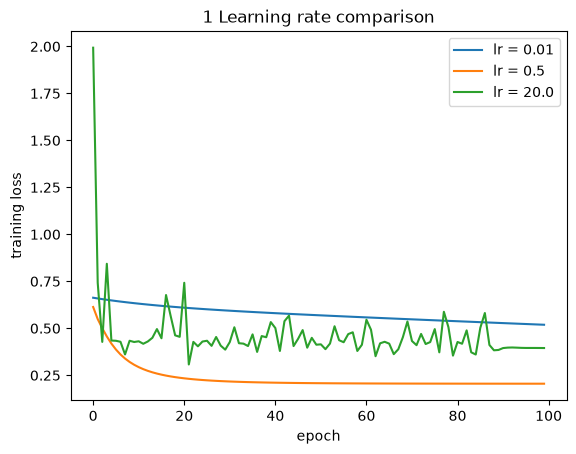

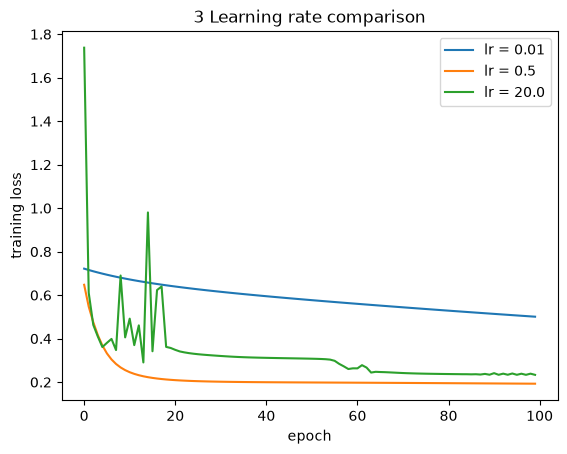

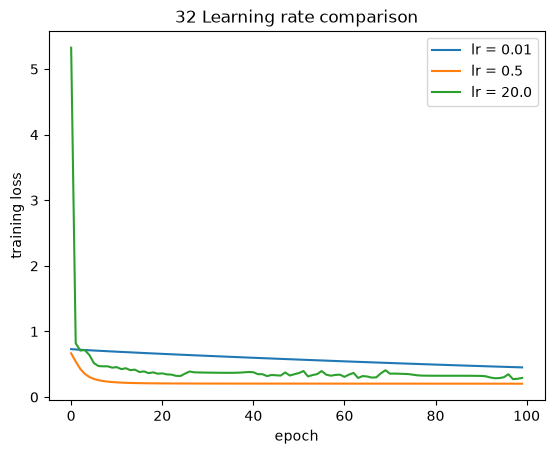

In [16]:
def build(nsize):
    m = tf.keras.Sequential([
        tf.keras.Input(shape=(2,)),
        tf.keras.layers.Normalization(),
        tf.keras.layers.Dense(nsize, activation="sigmoid"),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ])
    m.layers[0].adapt(X_train)
    return m

for nsize in [1, 3, 32]: 
    for lr in [0.01, 0.5, 20.0]:
        tf.keras.utils.set_random_seed(173)
        m = build(nsize)
        m.compile(optimizer=tf.keras.optimizers.SGD(learning_rate=lr), loss="binary_crossentropy")
        h = m.fit(X_train, y_train, epochs=100, batch_size=16, verbose=0)
        plt.plot(h.history["loss"], label=f"lr = {lr}")
    plt.xlabel("epoch"); plt.ylabel("training loss"); plt.legend(); plt.title(f"{nsize} Learning rate comparison")
    plt.show()

## Exercise 4. **Network size:** try 1, 3 and 32 hidden units. Compare training accuracy with test accuracy. What do you notice with 32?

With 1 hidden unit, training loss decereases slowly. For the learning rate of 0.01, it reaches approximately 0.5 after 100 epochs while the learning rate of 0.5 stabilizes at around 0.2 at 20 epochs. As can be observed however, the learning rate of 20 have exhibited instability and constant fluctuation, stabilizing only at around 90 epochs.

With 3 hidden units, training loss decreases faster and also exhibits earlier stabilization of learning. At 0.01 learnming rate, it readily enters a constant slope reaching into 0.6 at 100 epochs which is still greater than that of 1 hidden unit. At learning rate 0.5, it exhibited the same trend as that of 1 hidden unit. The greater difference can be seen at learning rate 20 wherein it stabilized at 20 epochs already.

With 32 hidden units, training loss stabilizes quickly. At 0.01 learning rate, it enters a relatively linear slope towards the end at approximately 0.5. Meanwhile, the learning rate of 0.5 exhibited the same trend. The difference however, lies in the learning rate of 20 wherein it incurred the highest initial training loss at >5. Nevertheless, this immediately dropped at around 5 epochs, with minor fluctuations towards 100 epochs. 

This means that the 32 hidden units allowed for a greater capacity to learn and stabilize. However, it is prone to overfitting. Moreover, the learning rate has been observed to incur the greatest instabilities across all tests. 

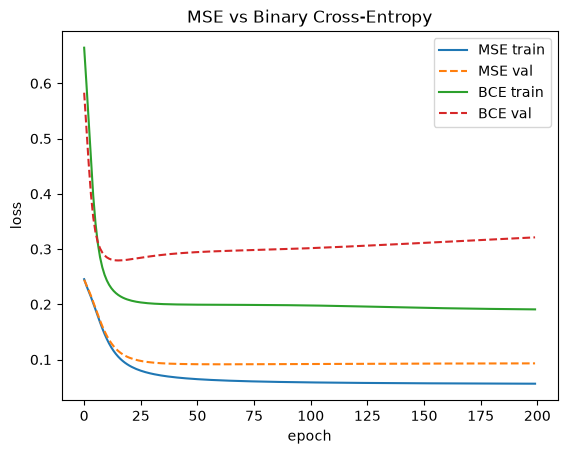

In [17]:
model_mse = tf.keras.Sequential([
    tf.keras.Input(shape=(2,)),
    tf.keras.layers.Normalization(),
    tf.keras.layers.Dense(3, activation="sigmoid"),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])
model_mse.layers[0].adapt(X_train)
model_mse.compile(optimizer=tf.keras.optimizers.SGD(0.5), loss="mse", metrics=["accuracy"])
h_mse = model_mse.fit(X_train, y_train, epochs=200, batch_size=16, validation_data=(X_test, y_test), verbose=0)

model_bce = tf.keras.Sequential([
    tf.keras.Input(shape=(2,)),
    tf.keras.layers.Normalization(),
    tf.keras.layers.Dense(3, activation="sigmoid"),
    tf.keras.layers.Dense(1, activation="sigmoid"),
])
model_bce.layers[0].adapt(X_train)
model_bce.compile(optimizer=tf.keras.optimizers.SGD(0.5), loss="binary_crossentropy", metrics=["accuracy"])
h_bce = model_bce.fit(X_train, y_train, epochs=200, batch_size=16, validation_data=(X_test, y_test), verbose=0)

plt.plot(h_mse.history["loss"], label="MSE train")
plt.plot(h_mse.history["val_loss"], label="MSE val", linestyle="--")
plt.plot(h_bce.history["loss"], label="BCE train")
plt.plot(h_bce.history["val_loss"], label="BCE val", linestyle="--")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("MSE vs Binary Cross-Entropy")
plt.show()


## Exercise 5. **Loss:** change the loss to `"mse"` and compare the learning curve with cross-entropy.

As can be observed in the plot above, MSE have yielded a more gradual decrease in loss for both training and validation whereas BCE started off with greater losses then immediately dropped to a significantly lower loss to which it then stabilizes early. However, it can also be observed that both the training and validation loss curves eventually diverge towards 200 epochs which suggests that the model is leaning on overfitting for both models, becoming more and more attuned to training data but incurring more errors with new, unseen test data. This is particularly obvious for the BCE curves. Moreover, MSE has exhibited lower losses in all accords than BCE.


## Exercise 6. **Backprop by hand:** using section 3, compute $\partial E / \partial w_6$ on paper, then check it with `tape.gradient(E, w6)`.

![Solve for Error](ex6p1.jpg)   
![Solve for w6](ex6p2.jpg)   

Values have been solved accordingly and yielded the same results as tape.gradient(E, w6).

---
## 6. Exercises

1. **Perceptron:** in section 1, find an input $X$ that gives exactly $\hat{y} = 0.5$. (Hint: it must lie on the line $1 + 3x_1 - 2x_2 = 0$.)
2. **Activations:** in section 5, change the hidden activation from `"sigmoid"` to `"relu"`. Does training get faster?
3. **Batch size:** train with `batch_size=1` (stochastic), `16` (mini-batch) and `150` (full batch). Compare the loss curves and the time taken.
4. **Network size:** try 1, 3 and 32 hidden units. Compare training accuracy with test accuracy. What do you notice with 32?
5. **Loss:** change the loss to `"mse"` and compare the learning curve with cross-entropy.
6. **Backprop by hand:** using section 3, compute $\partial E / \partial w_6$ on paper, then check it with `tape.gradient(E, w6)`.